# U-Net

### Colab에서 진행 시

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pwd

/content


In [3]:
%cd /content/drive/MyDrive/Lecture_2024_DeepLerning/UNet_실습

/content/drive/MyDrive/Lecture_2024_DeepLerning/UNet_실습


In [ ]:
!unzip -qq "./data.zip"

replace data/test/images/008_HC.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

### 1. 라이브러리

In [ ]:
import os
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import random
from glob import glob
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision.transforms.functional import to_pil_image
import torch.nn.functional as F
import time
from torchsummary import summary

In [ ]:
torch.cuda.is_available() #gpu 확인


True

In [ ]:
device = torch.device('cuda')
print(device)

cuda


### 2. seed 고정/폴더 생성

In [ ]:
def seeding(seed):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

""" Create a directory. """
def create_dir(path):
    if not os.path.exists(path):
        os.makedirs(path)

In [ ]:
""" Seeding """
seeding(42) #seed 고정

""" Directories """
create_dir("weights") #학습된 가중치 저장 디렉토리 생성

create_dir("results") #테스트 데이터 결과 저장 디렉토리 생성

### 3. 데이터 불러오기/전처리

In [ ]:
class DriveDataset(Dataset):
    def __init__(self, images_path, masks_path, device):

        self.images_path = images_path
        self.masks_path = masks_path
        self.n_samples = len(images_path)

    def __getitem__(self, index):
        """ Reading image """
        image = cv2.imread(self.images_path[index], cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (256, 256))## (256, 256, 1)
        image = image/255.0
        image = np.expand_dims(image, axis=0) ## (1, 256, 256)
        image = image.astype(np.float32)
        image = torch.from_numpy(image)

        """ Reading mask """
        mask = cv2.imread(self.masks_path[index], cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (256, 256))
        mask = mask/255.0
        mask[mask>=0.5]=1
        mask[mask<0.5]=0
        mask = np.expand_dims(mask, axis=0) ## (1, 256, 256)
        mask = mask.astype(np.float32)
        mask = torch.from_numpy(mask)


        return image, mask

    def __len__(self):
        return self.n_samples

In [ ]:

""" Hyperparameters """
batch_size = 2
num_epochs = 2      # 10인데 오래 걸려서 2로 바꿈
lr = 1e-4
checkpoint_path = "./weights/checkpoint.pth"

""" Load dataset """
train_x = sorted(glob("./data/train/images/*"))
train_y = sorted(glob("./data/train/masks/*"))

valid_x = sorted(glob("./data/validate/images/*"))
valid_y = sorted(glob("./data/validate/masks/*"))

data_str = f"Dataset Size:\nTrain: {len(train_x)} - Valid: {len(valid_x)}\n"
print(data_str)


""" Dataset and loader """
train_dataset = DriveDataset(train_x, train_y, device)
valid_dataset = DriveDataset(valid_x, valid_y, device)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

valid_loader = DataLoader(
    dataset=valid_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)


Dataset Size:
Train: 629 - Valid: 270



#### 데이터 시각화

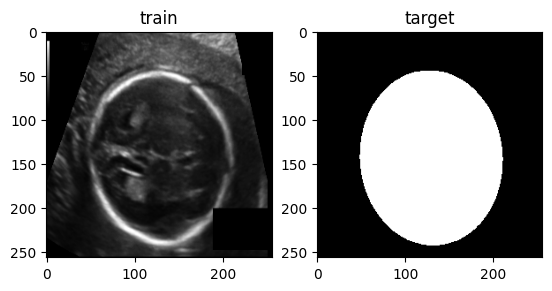

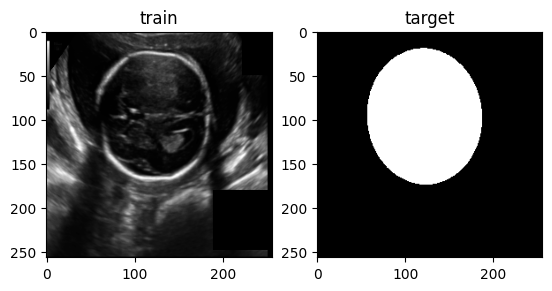

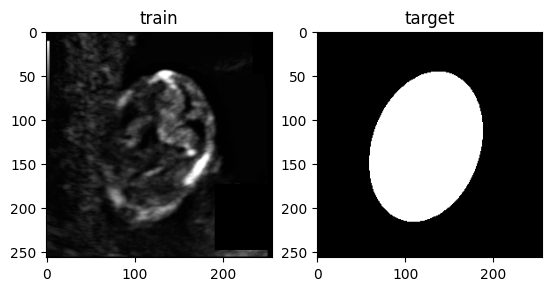

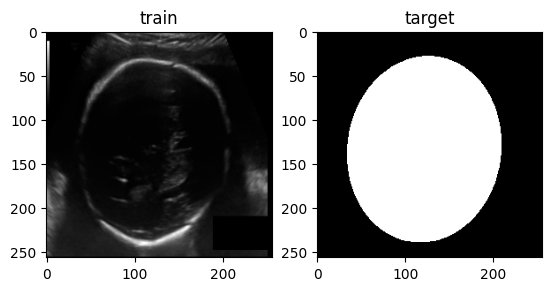

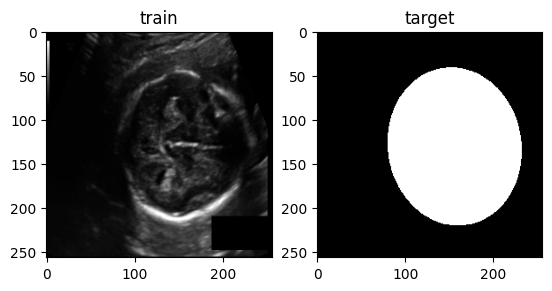

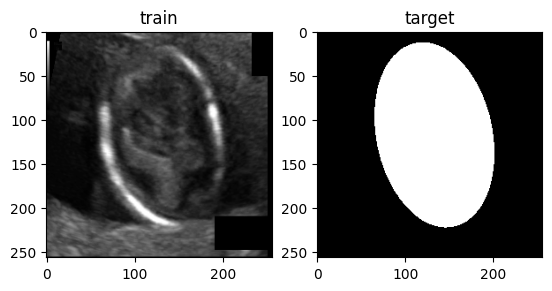

In [ ]:

for j in range(3):
    image, labels = next(iter(train_loader))
    for i in range(2):
        plt.figure()
        plt.subplot(1,2,1)
        plt.imshow(to_pil_image(image[i]), cmap='gray')
        plt.title('train')
        plt.subplot(1,2,2)
        plt.imshow(to_pil_image(labels[i]), cmap='gray')
        plt.title('target')

### 4. 모델 정의하기

In [ ]:
class conv_block(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_c)

        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_c)

        self.relu = nn.ReLU()

    def forward(self, inputs):
        x = self.conv1(inputs)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x)
        x = self.relu(x)

        return x

class encoder_block(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.conv = conv_block(in_c, out_c)
        self.pool = nn.MaxPool2d((2, 2))

    def forward(self, inputs):
        x = self.conv(inputs)
        p = self.pool(x)

        return x, p

class decoder_block(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()

        self.up = nn.ConvTranspose2d(in_c, out_c, kernel_size=2, stride=2, padding=0)
        self.conv = conv_block(out_c+out_c, out_c)

    def forward(self, inputs, skip):
        x = self.up(inputs)
        x = torch.cat([x, skip], axis=1)
        x = self.conv(x)
        return x

class build_unet(nn.Module):
    def __init__(self):
        super().__init__()

        """ Encoder """
        self.e1 = encoder_block(1, 64)
        self.e2 = encoder_block(64, 128)
        self.e3 = encoder_block(128, 256)
        self.e4 = encoder_block(256, 512)

        """ Bottleneck """
        self.b = conv_block(512, 1024)

        """ Decoder """
        self.d1 = decoder_block(1024, 512)
        self.d2 = decoder_block(512, 256)
        self.d3 = decoder_block(256, 128)
        self.d4 = decoder_block(128, 64)

        """ Classifier """
        self.outputs = nn.Conv2d(64, 1, kernel_size=1, padding=0)

    def forward(self, inputs):
        """ Encoder """
        s1, p1 = self.e1(inputs)
        s2, p2 = self.e2(p1)
        s3, p3 = self.e3(p2)
        s4, p4 = self.e4(p3)

        """ Bottleneck """
        b = self.b(p4)

        """ Decoder """
        d1 = self.d1(b, s4)
        d2 = self.d2(d1, s3)
        d3 = self.d3(d2, s2)
        d4 = self.d4(d3, s1)

        outputs = self.outputs(d4)

        return outputs

In [ ]:

""" Calculate the time taken """
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs


In [ ]:
class DiceBCELoss(nn.Module):
    def __init__(self, weight=None, size_average=True):
        super(DiceBCELoss, self).__init__()

    def forward(self, inputs, targets, smooth=1):

        #comment out if your model contains a sigmoid or equivalent activation layer
        inputs = torch.sigmoid(inputs)

        #flatten label and prediction tensors
        inputs = inputs.view(-1)
        targets = targets.view(-1)

        intersection = (inputs * targets).sum()
        dice_loss = 1 - (2.*intersection + smooth)/(inputs.sum() + targets.sum() + smooth)
        BCE = F.binary_cross_entropy(inputs, targets, reduction='mean')
        Dice_BCE = BCE + dice_loss

        return Dice_BCE

In [ ]:

 ## GTX 1060 6GB
model = build_unet()
model = model.to(device)
summary(model, (1, 256, 256),batch_size=2)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', patience=5, verbose=True)
loss_fn = DiceBCELoss()

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [2, 64, 256, 256]             640
       BatchNorm2d-2          [2, 64, 256, 256]             128
              ReLU-3          [2, 64, 256, 256]               0
            Conv2d-4          [2, 64, 256, 256]          36,928
       BatchNorm2d-5          [2, 64, 256, 256]             128
              ReLU-6          [2, 64, 256, 256]               0
        conv_block-7          [2, 64, 256, 256]               0
         MaxPool2d-8          [2, 64, 128, 128]               0
     encoder_block-9  [[-1, 64, 256, 256], [-1, 64, 128, 128]]               0
           Conv2d-10         [2, 128, 128, 128]          73,856
      BatchNorm2d-11         [2, 128, 128, 128]             256
             ReLU-12         [2, 128, 128, 128]               0
           Conv2d-13         [2, 128, 128, 128]         147,584
      BatchNorm2d-14    

### 5. 학습

In [ ]:

def train(model, loader, optimizer, loss_fn, device):
    epoch_loss = 0.0

    model.train()
    for x, y in loader:
        x = x.to(device, dtype=torch.float32)
        y = y.to(device, dtype=torch.float32)

        optimizer.zero_grad()
        y_pred = model(x)
        loss = loss_fn(y_pred, y)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    epoch_loss = epoch_loss/len(loader)
    return epoch_loss

def evaluate(model, loader, loss_fn, device):
    epoch_loss = 0.0

    model.eval()
    with torch.no_grad():
        for x, y in loader:
            x = x.to(device, dtype=torch.float32)
            y = y.to(device, dtype=torch.float32)

            y_pred = model(x)
            loss = loss_fn(y_pred, y)
            epoch_loss += loss.item()

        epoch_loss = epoch_loss/len(loader)
    return epoch_loss


In [ ]:
""" Training the model """
best_valid_loss = float("inf")

for epoch in range(num_epochs):
    start_time = time.time()

    train_loss = train(model, train_loader, optimizer, loss_fn, device)
    valid_loss = evaluate(model, valid_loader, loss_fn, device)

    """ Saving the model """
    if valid_loss < best_valid_loss:
        data_str = f"Valid loss improved from {best_valid_loss:2.4f} to {valid_loss:2.4f}. Saving checkpoint: {checkpoint_path}"
        print(data_str)

        best_valid_loss = valid_loss
        torch.save(model.state_dict(), checkpoint_path)

    end_time = time.time()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    data_str = f'Epoch: {epoch+1:02} | Epoch Time: {epoch_mins}m {epoch_secs}s\n'
    data_str += f'\tTrain Loss: {train_loss:.3f}\n'
    data_str += f'\t Val. Loss: {valid_loss:.3f}\n'
    print(data_str)

Valid loss improved from inf to 0.3434. Saving checkpoint: ./weights/checkpoint.pth
Epoch: 01 | Epoch Time: 1m 22s
	Train Loss: 0.502
	 Val. Loss: 0.343

Valid loss improved from 0.3434 to 0.1924. Saving checkpoint: ./weights/checkpoint.pth
Epoch: 02 | Epoch Time: 1m 18s
	Train Loss: 0.250
	 Val. Loss: 0.192



### 6. 테스트

In [ ]:
from tqdm import tqdm
from operator import add
from torchvision.utils import save_image
from sklearn.metrics import accuracy_score, f1_score, jaccard_score, precision_score, recall_score
import torchvision
import torchvision.transforms.functional as Ff

In [ ]:

def calculate_metrics(y_true, y_pred):
    """ Ground truth """
    y_true = y_true.cpu().numpy()
    y_true = y_true > 0.5
    y_true = y_true.astype(np.uint8)

    """ Prediction """
    y_pred = y_pred.cpu().numpy()
    y_pred = y_pred > 0.5
    y_pred = y_pred.astype(np.uint8)

    y_true = y_true.reshape(-1)
    y_pred = y_pred.reshape(-1)

    score_jaccard = jaccard_score(y_true, y_pred)
    score_f1 = f1_score(y_true, y_pred)
    score_acc = accuracy_score(y_true, y_pred)
    return [score_jaccard, score_f1, score_acc]

In [ ]:


""" Load dataset """
test_x = sorted(glob("./data/test/images/*"))
test_y = sorted(glob("./data/test/masks/*"))

""" Hyperparameters """

checkpoint_path = "./weights/checkpoint.pth" #테스트할 모델

""" Load the checkpoint """
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = build_unet()
model = model.to(device)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

metrics_score = [0.0, 0.0, 0.0]
time_taken = []

for i, (x, y) in tqdm(enumerate(zip(test_x, test_y)), total=len(test_x)):
    """ Extract the name """
    name = x.split("/")[-1].split(".")[0] ## \\ 또는 /로
    """ Reading image """
    image = cv2.imread(x, cv2.IMREAD_GRAYSCALE) ## (256, 256)
    image = cv2.resize(image, (256, 256))
    x = np.expand_dims(image, axis=0)     ## (1, 256, 256)
    x = x/255.0
    x = np.expand_dims(x, axis=0)           ## (1, 1, 256, 256)
    x = x.astype(np.float32)
    x = torch.from_numpy(x)
    x = x.to(device)

    """ Reading mask """
    mask = cv2.imread(y, cv2.IMREAD_GRAYSCALE)  ## (256, 256)
    mask = cv2.resize(mask, (256, 256))
    y = np.expand_dims(mask, axis=0)
    y = y/255.0
    y[y>=0.5]=1
    y[y<0.5]=0
    y = np.expand_dims(y, axis=0)               ## (1, 1, 256, 256)
    y = y.astype(np.float32)
    y = torch.from_numpy(y)
    y = y.to(device)

    with torch.no_grad():
        """ Prediction and Calculating FPS """
        start_time = time.time()
        pred_y = model(x)
        pred_y = torch.sigmoid(pred_y)
        total_time = time.time() - start_time
        time_taken.append(total_time)


        score = calculate_metrics(y, pred_y)
        metrics_score = list(map(add, metrics_score, score))
        pred_y = pred_y[0].cpu().numpy()        ## (1, 256, 256)
        pred_y = np.squeeze(pred_y, axis=0)     ## (256, 256)
        pred_y = pred_y > 0.5
        pred_y = np.array(pred_y, dtype=np.uint8)

        p = torch.Tensor(pred_y)
        save_image(p, f'results/{name}_pred.png')

jaccard = metrics_score[0]/len(test_x)
f1 = metrics_score[1]/len(test_x)
acc = metrics_score[2]/len(test_x)

print(f"Jaccard index(IoU): {jaccard:1.4f} - F1(Dice Coefficient): {f1:1.4f} - Acc: {acc:1.4f}")

fps = 1/np.mean(time_taken)
print("FPS: ", fps)

100%|██████████| 100/100 [00:19<00:00,  5.05it/s]

Jaccard index(IoU): 0.8982 - F1(Dice Coefficient): 0.9423 - Acc: 0.9753
FPS:  130.6194851212331


### 테스트 데이터 예측 결과  시각화

In [ ]:
def show(gt, pred, name):
        plt.figure()
        plt.subplot(1,2,1)
        gt = gt.detach()
        gt = Ff.to_pil_image(gt)
        plt.imshow(np.asarray(gt))
        plt.title(f'{name} Ground Truth')
        plt.subplot(1,2,2)
        pred = pred.detach()
        pred = Ff.to_pil_image(pred)
        plt.imshow(np.asarray(pred))
        plt.title(f'{name} Prediction')

In [ ]:
pred_mask = sorted(glob('./results/*'))

In [ ]:
n=30
for i, (x, y) in enumerate(zip(test_x[n:], test_y[n:])):
    name = x.split("/")[-1].split(".")[0]
    img = cv2.imread(x)
    h,w = img.shape[0], img.shape[1]
    gt = cv2.imread(y, cv2.IMREAD_GRAYSCALE)
    gt = cv2.resize(gt, (w,h))
    pred = cv2.imread(f"./results/{name}_pred.png", cv2.IMREAD_GRAYSCALE)
    pred = cv2.resize(pred, (w,h))
    img = torch.from_numpy(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)).permute(2,0,1)
    gt = torch.from_numpy(gt)
    pred = torch.from_numpy(pred)
    gt[gt<=128] = False
    gt[gt>128] = True
    pred[pred<=128] = False
    pred[pred>128] = True
    gt = torch.tensor(gt, dtype=bool)
    pred = torch.tensor(pred, dtype=bool)
    img_gt = torchvision.utils.draw_segmentation_masks(img, gt, alpha=0.35, colors=(0,255,0))
    img_pred  = torchvision.utils.draw_segmentation_masks(img, pred, alpha=0.35, colors=(255,0,0))
    show(img_gt, img_pred, name)

Output hidden; open in https://colab.research.google.com to view.